# Regressão polinomial

A regressão linear com **polynomial features** é uma técnica utilizada para modelar relações não-lineares entre variáveis preditoras (features) e a variável de resposta, ampliando a capacidade da regressão linear tradicional. Embora o nome "regressão linear" sugira que o modelo lida apenas com relações lineares, isso se refere à linearidade dos **coeficientes** (pesos $ w $) em relação às variáveis, e não à forma como essas variáveis aparecem na equação. Isso significa que a relação entre as variáveis e a saída pode ser não-linear, desde que os coeficientes $ w_0, w_1, \dots, w_n $ permaneçam lineares no modelo.

### Como funciona:
Na regressão linear padrão, o modelo ajusta uma função da forma $ y = w_0 + w_1x_1 + \dots + w_nx_n $, onde $ x_1, x_2, \dots, x_n $ são as variáveis preditoras e $ w_0, w_1, \dots, w_n $ são os coeficientes que o modelo aprende. A "linearidade" aqui se refere ao fato de que a equação é linear em relação aos coeficientes $ w $, ou seja, cada coeficiente multiplica uma variável ou uma combinação de variáveis diretamente.

Quando utilizamos **polynomial features**, introduzimos novas features elevando as variáveis originais a diferentes potências. Por exemplo, para um modelo com uma única variável $ x $ e grau 2, o modelo se torna:
$$ y = w_0 + w_1x + w_2x^2 $$
Agora o modelo ajusta uma parábola em vez de uma linha reta, mas ainda assim continua sendo linear em relação aos coeficientes $ w_0, w_1, w_2 $.

Esse conceito pode ser expandido para múltiplas variáveis e para graus maiores. Para um grau 3 com duas variáveis $ x_1 $ e $ x_2 $, o modelo incluiria termos como $ x_1^2 $, $ x_1x_2 $, $ x_2^3 $, e assim por diante.

### PolynomialFeatures no Scikit-Learn:
No Scikit-Learn, a transformação de dados para incluir essas novas features polinomiais é feita através do `PolynomialFeatures`, um transformador que gera automaticamente todas as combinações de variáveis até o grau especificado. Esse transformador é geralmente utilizado em conjunto com um regressor linear para criar o modelo final.

https://scikit-learn.org/stable/modules/linear_model.html#polynomial-regression-extending-linear-models-with-basis-functions

https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html#sklearn.preprocessing.PolynomialFeatures


### Benefícios:
- **Modelar relações não-lineares**: Adicionando termos polinomiais, o modelo pode capturar padrões mais complexos nos dados.
- **Simplicidade**: Apesar de aumentar a complexidade do modelo, o conceito ainda é baseado na regressão linear, o que facilita a interpretação e a implementação.

### Desvantagens:
- **Overfitting**: Com graus muito altos, o modelo pode se ajustar demais aos dados de treino, capturando ruído em vez de padrões genuínos.
- **Crescimento exponencial das features**: À medida que o grau aumenta, o número de termos polinomiais cresce rapidamente, o que pode tornar o modelo mais difícil de treinar e interpretar.

Portanto, a regressão linear com **polynomial features** é uma maneira eficaz de lidar com relações não-lineares, mantendo a linearidade em relação aos coeficientes $ w $. Essa técnica oferece uma solução balanceada para problemas onde a relação entre as variáveis preditoras e a variável de resposta é complexa, mas ainda acessível para interpretação e implementação.

## 1. Ambiente e importações

Execute esta célula primeiro, usando o kernel **machine_learn**. Ela localiza o módulo, prepara o caminho do pacote `polinomial` e mostra qual Python e qual arquivo de dados estão em uso.

Este notebook importa apenas as bibliotecas e a configuração necessárias para o exemplo.

In [1]:
import sys
from pathlib import Path

# Encontra o módulo e disponibiliza seu pacote Python, sem depender da pasta atual.
from pathlib import Path
PASTA_ATUAL = Path.cwd().resolve()
PASTA_PROJETO = next(
    (
        pasta
        for base in (PASTA_ATUAL, *PASTA_ATUAL.parents)
        for pasta in (
            base,
            base / "04_regressao_polinomial",
            base / "regressao_modelos_lineares" / "04_regressao_polinomial",
        )
        if (pasta / "src" / "polinomial" / "config.py").is_file()
    ),
    None,
)
if PASTA_PROJETO is None:
    raise FileNotFoundError("Não foi possível localizar o módulo 04_regressao_polinomial.")
PASTA_SRC = PASTA_PROJETO / "src"
# Dá prioridade ao código deste projeto no caminho de importação.
if str(PASTA_SRC) in sys.path:
    sys.path.remove(str(PASTA_SRC))
sys.path.insert(0, str(PASTA_SRC))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

from polinomial.config import DADOS_EXEMPLO_POLINOMIAL

sns.set_theme(palette="bright")
RANDOM_STATE = 1

print(f"Python do kernel: {sys.executable}")
print(f"Dados da aula: {DADOS_EXEMPLO_POLINOMIAL}")

Python do kernel: /home/paulo-vinicius/miniconda3/envs/machine_learn/bin/python
Dados da aula: /home/paulo-vinicius/Documentos/Ciência de Dados/Machine_Learning/regressao_modelos_lineares/04_regressao_polinomial/dados/dados_polinomial.csv


## 2. Dados da aula

O arquivo `dados_polinomial.csv` contém a variável de entrada `X` e o alvo `y`. O caminho vem da configuração do módulo e funciona sem depender da pasta Downloads.

In [2]:
df = pd.read_csv(DADOS_EXEMPLO_POLINOMIAL)
df.head()

,X,y
0,0.261961,7.620010
1,0.903381,8.254397
2,0.020782,2.712432
3,0.899936,8.855505
4,0.097239,5.699531


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       100 non-null    float64
 1   y       100 non-null    float64
dtypes: float64(2)
memory usage: 1.7 KB


## 3. Separação entre treino e teste

Reservamos 25% dos dados para teste. Todos os graus usam a mesma divisão para tornar a comparação consistente. Os dados de teste aparecem nos gráficos, mas não são usados no ajuste dos modelos.

In [4]:
X = df[["X"]]
y = df["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE,
)

# Pontos ordenados apenas para desenhar as curvas de predição.
xfit = np.linspace(-0.1, 1.1, 1000)
df_xfit = pd.DataFrame({"X": xfit})

ordens = (1, 3, 8)
titulos = tuple(f"Grau {ordem}" for ordem in ordens)

## 4. Um pipeline independente para cada grau

Cada pipeline expande `X` com PolynomialFeatures e ajusta uma **nova instância** de LinearRegression. Assim, o ajuste de grau 8 preserva os modelos de graus 1 e 3.

Guardamos o modelo, os coeficientes e o intercepto para reutilização nas próximas células.

In [5]:
parametros_modelos = {}

for ordem, titulo in zip(ordens, titulos):
    modelo = Pipeline([
        ("poly", PolynomialFeatures(degree=ordem, include_bias=False)),
        ("reg", LinearRegression()),
    ])
    modelo.fit(X_train, y_train)

    parametros_modelos[titulo] = {
        "modelo": modelo,
        "coef": modelo["reg"].coef_.copy(),
        "intercept": modelo["reg"].intercept_,
    }

pd.DataFrame({
    titulo: {"numero_coeficientes": len(info["coef"]), "intercepto": info["intercept"]}
    for titulo, info in parametros_modelos.items()
}).T

,numero_coeficientes,intercepto
Grau 1,1.0,3.336797
Grau 3,3.0,1.021287
Grau 8,8.0,0.247612


## 5. Comparação visual

Cada coluna corresponde a um grau. As linhas mostram, respectivamente, treino e teste juntos, apenas treino e apenas teste. A curva de cada modelo é a mesma nas três linhas, pois reutilizamos o pipeline já treinado.

O grau 1 produz uma reta; graus maiores permitem mais curvatura. Use também métricas e validação cruzada antes de escolher um grau.

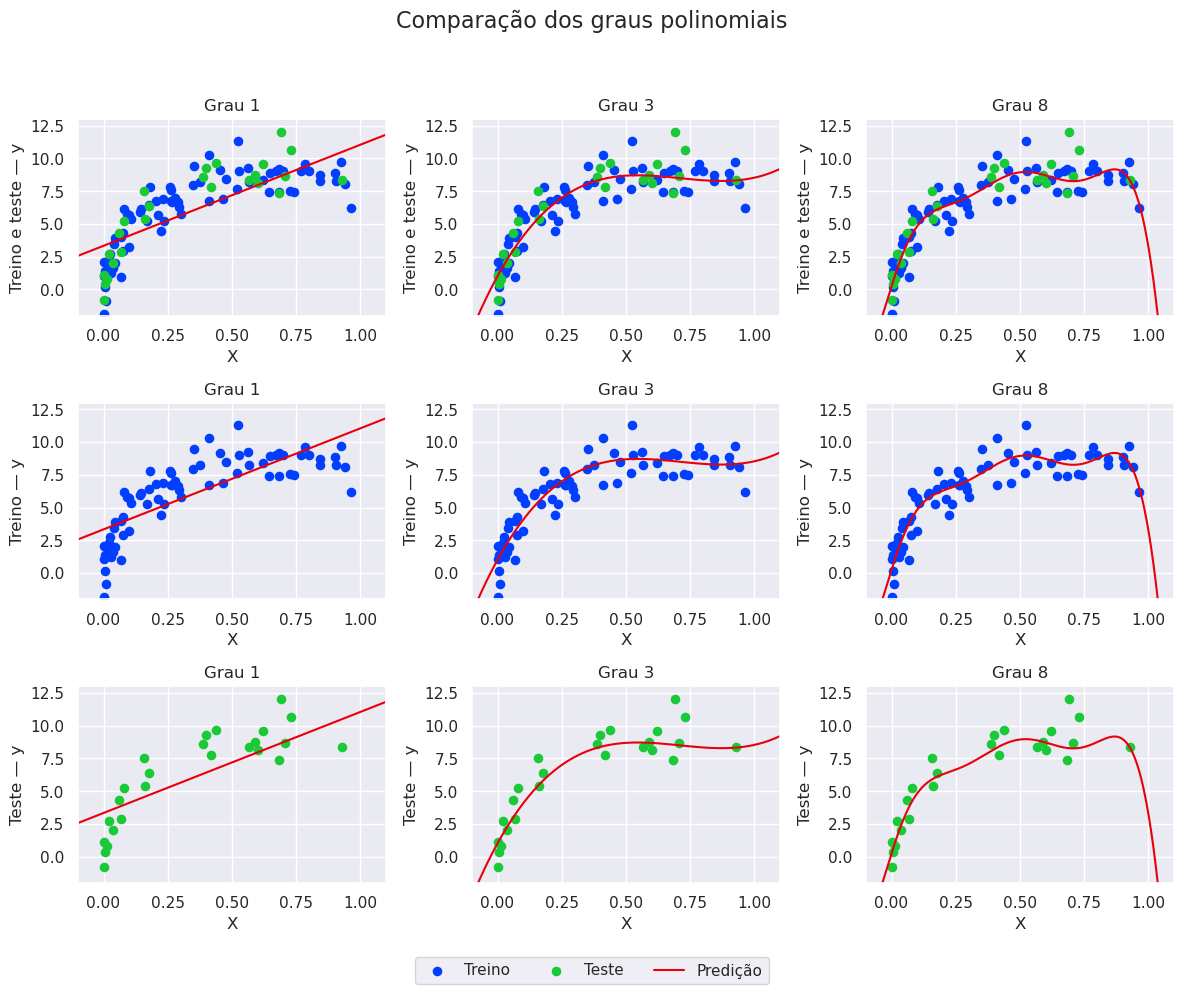

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
rotulos_linhas = ("Treino e teste", "Treino", "Teste")

for coluna, titulo in enumerate(titulos):
    modelo = parametros_modelos[titulo]["modelo"]
    y_pred = modelo.predict(df_xfit)

    for linha, rotulo in enumerate(rotulos_linhas):
        ax = axes[linha, coluna]
        if linha in (0, 1):
            ax.scatter(X_train["X"], y_train, s=35, color="C0", label="Treino")
        if linha in (0, 2):
            ax.scatter(X_test["X"], y_test, s=35, color="C2", label="Teste")
        ax.plot(xfit, y_pred, color="C3", label="Predição")
        ax.set(
            title=titulo, xlim=(-0.1, 1.1), ylim=(-2, 13),
            xlabel="X", ylabel=f"{rotulo} — y",
        )

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.suptitle("Comparação dos graus polinomiais", fontsize=16)
fig.legend(handles, labels, loc="lower center", ncol=3)
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
plt.show()